In [1]:
#202431055_Muhammad Rafi Kurniawan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

pd.set_option('display.max_columns', None)

In [2]:
#202431055_Muhammad Rafi Kurniawan
data = pd.read_csv('heart.csv')
print('Ukuran data (baris, kolom):', data.shape)
data.head()

Ukuran data (baris, kolom): (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
#202431055_Muhammad Rafi Kurniawan
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [4]:
#202431055_Muhammad Rafi Kurniawan
data.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [5]:
#202431055_Muhammad Rafi Kurniawan

#   0 = pasien normal
#   1 = pasien terdiagnosis penyakit jantung

jumlah_kelas = data['HeartDisease'].value_counts()
persen_kelas = (data['HeartDisease'].value_counts(normalize=True) * 100).round(2)

print('Jumlah per kelas:')
print(jumlah_kelas)
print()
print('Persentase per kelas (%):')
print(persen_kelas)

Jumlah per kelas:
1    508
0    410
Name: HeartDisease, dtype: int64

Persentase per kelas (%):
1    55.34
0    44.66
Name: HeartDisease, dtype: float64


In [6]:
#202431055_Muhammad Rafi Kurniawan
data_bersih = data.copy()

print('Nilai kosong (NaN) per kolom, sebelum:')
print(data_bersih.isna().sum().sum(), 'nilai kosong')
print('Jumlah RestingBP = 0 :', (data_bersih['RestingBP'] == 0).sum())
print('Jumlah Cholesterol = 0:', (data_bersih['Cholesterol'] == 0).sum())
print('Jumlah baris duplikat :', data_bersih.duplicated().sum())

data_bersih = data_bersih.drop_duplicates()

data_bersih = data_bersih[data_bersih['RestingBP'] != 0]

data_bersih['Cholesterol'] = data_bersih['Cholesterol'].replace(0, np.nan)
median_kolesterol = data_bersih['Cholesterol'].median()
data_bersih['Cholesterol'] = data_bersih['Cholesterol'].fillna(median_kolesterol)
print('Median kolesterol untuk pengisian:', median_kolesterol)

data_bersih['Sex'] = data_bersih['Sex'].map({'F': 0, 'M': 1})
data_bersih['ExerciseAngina'] = data_bersih['ExerciseAngina'].map({'N': 0, 'Y': 1})
data_bersih = pd.get_dummies(data_bersih,
                             columns=['ChestPainType', 'RestingECG', 'ST_Slope'],
                             dtype=int)

data_bersih = data_bersih.reset_index(drop=True)

print()
print('Ukuran data sebelum :', data.shape)
print('Ukuran data sesudah :', data_bersih.shape)
print('Nilai kosong sesudah:', data_bersih.isna().sum().sum())
print('Cholesterol = 0 sesudah:', (data_bersih['Cholesterol'] == 0).sum())
print()
print('Tipe data (pastikan semuanya angka):')
print(data_bersih.dtypes.value_counts())

Nilai kosong (NaN) per kolom, sebelum:
0 nilai kosong
Jumlah RestingBP = 0 : 1
Jumlah Cholesterol = 0: 172
Jumlah baris duplikat : 0
Median kolesterol untuk pengisian: 237.0

Ukuran data sebelum : (918, 12)
Ukuran data sesudah : (917, 19)
Nilai kosong sesudah: 0
Cholesterol = 0 sesudah: 0

Tipe data (pastikan semuanya angka):
int32      10
int64       7
float64     2
dtype: int64


In [7]:
#202431055_Muhammad Rafi Kurniawan
data_bersih.head()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289.0,0,172,0,0.0,0,0,1,0,0,0,1,0,0,0,1
1,49,0,160,180.0,0,156,0,1.0,1,0,0,1,0,0,1,0,0,1,0
2,37,1,130,283.0,0,98,0,0.0,0,0,1,0,0,0,0,1,0,0,1
3,48,0,138,214.0,0,108,1,1.5,1,1,0,0,0,0,1,0,0,1,0
4,54,1,150,195.0,0,122,0,0.0,0,0,0,1,0,0,1,0,0,0,1


In [8]:
#202431055_Muhammad Rafi Kurniawan
X = data_bersih.drop(columns=['HeartDisease'])
y = data_bersih['HeartDisease']

X_latih, X_uji, y_latih, y_uji = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y
)

print('Jumlah fitur            :', X.shape[1])
print('Jumlah data latih       :', X_latih.shape[0])
print('Jumlah data uji         :', X_uji.shape[0])
print()
print('Proporsi kelas data latih:')
print(y_latih.value_counts(normalize=True).round(4))
print('Proporsi kelas data uji:')
print(y_uji.value_counts(normalize=True).round(4))

Jumlah fitur            : 18
Jumlah data latih       : 687
Jumlah data uji         : 230

Proporsi kelas data latih:
1    0.5531
0    0.4469
Name: HeartDisease, dtype: float64
Proporsi kelas data uji:
1    0.5522
0    0.4478
Name: HeartDisease, dtype: float64


In [9]:
#202431055_Muhammad Rafi Kurniawan
tabel_rentang = pd.DataFrame({
    'minimum': X_latih.min(),
    'maksimum': X_latih.max()
})
tabel_rentang['rentang'] = tabel_rentang['maksimum'] - tabel_rentang['minimum']
tabel_rentang = tabel_rentang.sort_values('rentang', ascending=False)
print(tabel_rentang)

fitur_terlebar = tabel_rentang['rentang'].idxmax()
print()
print('Fitur dengan rentang paling lebar:', fitur_terlebar)

                   minimum  maksimum  rentang
Cholesterol           85.0     603.0    518.0
MaxHR                 63.0     202.0    139.0
RestingBP             80.0     200.0    120.0
Age                   28.0      77.0     49.0
Oldpeak               -2.0       6.2      8.2
ChestPainType_TA       0.0       1.0      1.0
ST_Slope_Flat          0.0       1.0      1.0
ST_Slope_Down          0.0       1.0      1.0
RestingECG_ST          0.0       1.0      1.0
RestingECG_Normal      0.0       1.0      1.0
RestingECG_LVH         0.0       1.0      1.0
ChestPainType_ATA      0.0       1.0      1.0
ChestPainType_NAP      0.0       1.0      1.0
Sex                    0.0       1.0      1.0
ChestPainType_ASY      0.0       1.0      1.0
ExerciseAngina         0.0       1.0      1.0
FastingBS              0.0       1.0      1.0
ST_Slope_Up            0.0       1.0      1.0

Fitur dengan rentang paling lebar: Cholesterol


In [10]:
#202431055_Muhammad Rafi Kurniawan
pipeline_knn = Pipeline([
    ('skaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])
pipeline_knn

Pipeline(steps=[('skaler', StandardScaler()), ('knn', KNeighborsClassifier())])

In [11]:
#202431055_Muhammad Rafi Kurniawan
parameter_k = {'knn__n_neighbors': list(range(1, 20))}

pencarian_k = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=parameter_k,
    cv=5,
    scoring='accuracy'
)
pencarian_k.fit(X_latih, y_latih)

k_terbaik = pencarian_k.best_params_['knn__n_neighbors']
skor_cv_terbaik = pencarian_k.best_score_

print('k terbaik                     :', k_terbaik)
print(f'Skor validasi silang terbaik  : {skor_cv_terbaik:.4f}')

k terbaik                     : 19
Skor validasi silang terbaik  : 0.8603


In [12]:
#202431055_Muhammad Rafi Kurniawan
hasil_cv = pd.DataFrame({
    'k': pencarian_k.cv_results_['param_knn__n_neighbors'].data.astype(int),
    'skor_cv_rata_rata': pencarian_k.cv_results_['mean_test_score'].round(4),
    'simpangan_baku': pencarian_k.cv_results_['std_test_score'].round(4)
})
hasil_cv

,k,skor_cv_rata_rata,simpangan_baku
0,1,0.7830,0.0328
1,2,0.7758,0.0443
2,3,0.8253,0.0250
3,4,0.8093,0.0170
4,5,0.8282,0.0263
5,6,0.8180,0.0190
6,7,0.8399,0.0169
7,8,0.8385,0.0113
8,9,0.8428,0.0132
9,10,0.8414,0.0137


In [13]:
#202431055_Muhammad Rafi Kurniawan
model_akhir = Pipeline([
    ('skaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=k_terbaik))
])
model_akhir.fit(X_latih, y_latih)

prediksi_uji = model_akhir.predict(X_uji)

print('Contoh 10 prediksi pertama :', prediksi_uji[:10])
print('Label asli 10 data pertama :', y_uji.values[:10])

Contoh 10 prediksi pertama : [1 1 0 1 0 1 1 1 1 0]
Label asli 10 data pertama : [1 1 1 1 0 0 1 0 1 0]


In [14]:
#202431055_Muhammad Rafi Kurniawan
akurasi = accuracy_score(y_uji, prediksi_uji)
akurasi_dasar = y_uji.value_counts(normalize=True).max()

print(f'Akurasi model                                : {akurasi:.4f}')
print(f'Akurasi pembanding (selalu tebak kelas mayoritas): {akurasi_dasar:.4f}')
print()
print('Classification report:')
print(classification_report(y_uji, prediksi_uji,
                            target_names=['0 (normal)', '1 (penyakit jantung)'],
                            zero_division=0))

Akurasi model                                : 0.8565
Akurasi pembanding (selalu tebak kelas mayoritas): 0.5522

Classification report:
                      precision    recall  f1-score   support

          0 (normal)       0.83      0.85      0.84       103
1 (penyakit jantung)       0.88      0.86      0.87       127

            accuracy                           0.86       230
           macro avg       0.85      0.86      0.86       230
        weighted avg       0.86      0.86      0.86       230



Confusion matrix (baris = label asli, kolom = prediksi):
                  Prediksi 0  Prediksi 1
Asli 0 (normal)           88          15
Asli 1 (jantung)          18         109


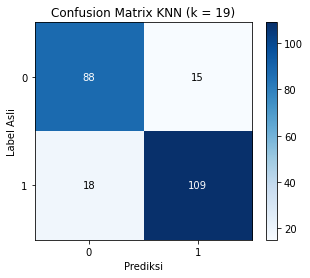

In [15]:
#202431055_Muhammad Rafi Kurniawan
matriks_konfusi = confusion_matrix(y_uji, prediksi_uji)
print('Confusion matrix (baris = label asli, kolom = prediksi):')
print(pd.DataFrame(matriks_konfusi,
                   index=['Asli 0 (normal)', 'Asli 1 (jantung)'],
                   columns=['Prediksi 0', 'Prediksi 1']))

plt.figure(figsize=(5, 4))
plt.imshow(matriks_konfusi, cmap='Blues')
plt.title(f'Confusion Matrix KNN (k = {k_terbaik})')
plt.xlabel('Prediksi')
plt.ylabel('Label Asli')
plt.xticks([0, 1], ['0', '1'])
plt.yticks([0, 1], ['0', '1'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, matriks_konfusi[i, j], ha='center', va='center',
                 color='white' if matriks_konfusi[i, j] > matriks_konfusi.max() / 2 else 'black')
plt.colorbar()
plt.show()

In [16]:
laporan = classification_report(y_uji, prediksi_uji, output_dict=True, zero_division=0)
print(f"Precision kelas 1 : {laporan['1']['precision']:.4f}")
print(f"Recall kelas 1    : {laporan['1']['recall']:.4f}")

Precision kelas 1 : 0.8790
Recall kelas 1    : 0.8583


In [17]:
#202431055_Muhammad Rafi Kurniawan
nilai_pasien = {
    'Age': 55,
    'Sex': 1,
    'RestingBP': 130,
    'Cholesterol': 240,
    'FastingBS': 0,
    'MaxHR': 140,
    'ExerciseAngina': 1,
    'Oldpeak': 1.0,
    'ChestPainType_ASY': 1, 'ChestPainType_ATA': 0, 'ChestPainType_NAP': 0, 'ChestPainType_TA': 0,
    'RestingECG_LVH': 0, 'RestingECG_Normal': 1, 'RestingECG_ST': 0,
    'ST_Slope_Down': 0, 'ST_Slope_Flat': 1, 'ST_Slope_Up': 0,
}

titik_baru = pd.DataFrame([nilai_pasien])[X_latih.columns]

dalam_rentang = (titik_baru.iloc[0] >= X_latih.min()) & (titik_baru.iloc[0] <= X_latih.max())
print('Semua fitur berada dalam rentang data latih?', bool(dalam_rentang.all()))
print()
print(titik_baru.T)

Semua fitur berada dalam rentang data latih? True

                       0
Age                 55.0
Sex                  1.0
RestingBP          130.0
Cholesterol        240.0
FastingBS            0.0
MaxHR              140.0
ExerciseAngina       1.0
Oldpeak              1.0
ChestPainType_ASY    1.0
ChestPainType_ATA    0.0
ChestPainType_NAP    0.0
ChestPainType_TA     0.0
RestingECG_LVH       0.0
RestingECG_Normal    1.0
RestingECG_ST        0.0
ST_Slope_Down        0.0
ST_Slope_Flat        1.0
ST_Slope_Up          0.0


In [18]:
#202431055_Muhammad Rafi Kurniawan
prediksi_baru = model_akhir.predict(titik_baru)[0]
peluang_baru = model_akhir.predict_proba(titik_baru)[0]

nama_kelas = {0: 'normal', 1: 'penyakit jantung'}
print('Prediksi kelas  :', prediksi_baru, '->', nama_kelas[prediksi_baru])
print(f'Peluang kelas 0 : {peluang_baru[0]:.4f}')
print(f'Peluang kelas 1 : {peluang_baru[1]:.4f}')

Prediksi kelas  : 1 -> penyakit jantung
Peluang kelas 0 : 0.1579
Peluang kelas 1 : 0.8421


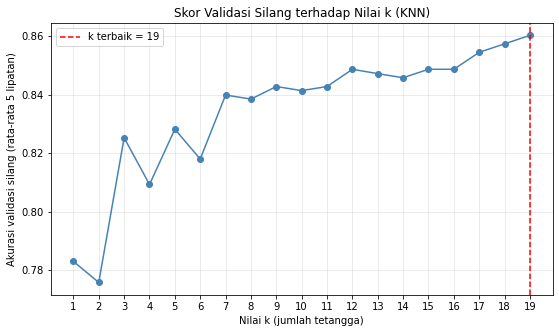

In [19]:
#202431055_Muhammad Rafi Kurniawan
plt.figure(figsize=(9, 5))
plt.plot(hasil_cv['k'], hasil_cv['skor_cv_rata_rata'], marker='o', color='steelblue')
plt.axvline(k_terbaik, color='red', linestyle='--', label=f'k terbaik = {k_terbaik}')
plt.title('Skor Validasi Silang terhadap Nilai k (KNN)')
plt.xlabel('Nilai k (jumlah tetangga)')
plt.ylabel('Akurasi validasi silang (rata-rata 5 lipatan)')
plt.xticks(range(1, 20))
plt.grid(alpha=0.3)
plt.legend()
plt.show()